In [1]:
%pip install pandas matplotlib seaborn numpy
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

Note: you may need to restart the kernel to use updated packages.


# 02. Serve dominance

The serve is the one shot a player fully controls. An ace is a serve the opponent does not touch. A double fault is two missed serves in a row, so the server loses the point without a rally. A break point is a chance for the returner to win the server's service game. Saving it means the server held on. This chapter compares winners and losers on those three ideas, then builds one combined score, the Serve Dominance Index.

In [2]:
import os
PROC = os.path.join('..', 'data', 'processed')
CH = os.path.join('..', 'charts')
os.makedirs(CH, exist_ok=True)

## How the Serve Dominance Index (SDI) works

SDI is an original metric for this project. For one player in one match: SDI = (aces + first serve points won - double faults) / service points played x 100. Read it as serve dominance points per 100 service points. First serve points won is derived, not printed in the file: it is the server's first serves in, minus the points the opponent won returning first serves. Service points played is first serves in divided by first serve percentage. Aces appear twice on purpose, once alone and once inside first serve points won, so big servers score higher. SDI is not a percentage.

In [3]:
df = pd.read_csv(f'{PROC}/slam_player_matches.csv')
print('Player match rows:', len(df))
print(df.groupby('winner')[['aces', 'dbl_faults', 'first_serve_per', 'first_won_rate', 'sdi']].mean().round(3))
print('Overall break points saved:', round(df.bp_saved.sum() / df.bp_faced.sum(), 4))
print(df.groupby('winner').apply(lambda x: round(x.bp_saved.sum() / x.bp_faced.sum(), 4)))

Player match rows: 20240
          aces  dbl_faults  first_serve_per  first_won_rate     sdi
winner                                                             
False    7.338       4.724            0.599           0.661  41.480
True    10.109       3.714            0.617           0.769  53.694
Overall break points saved: 0.6045
winner
False    0.5602
True     0.6812
dtype: float64


## Chart: aces by surface. Grass rewards the serve most, clay least.

           aces  dbl_faults  first_won_rate     sdi
surface                                            
Clay      6.163       3.623           0.688  44.264
Grass    10.726       4.236           0.740  52.212
Hard      9.004       4.509           0.716  46.934


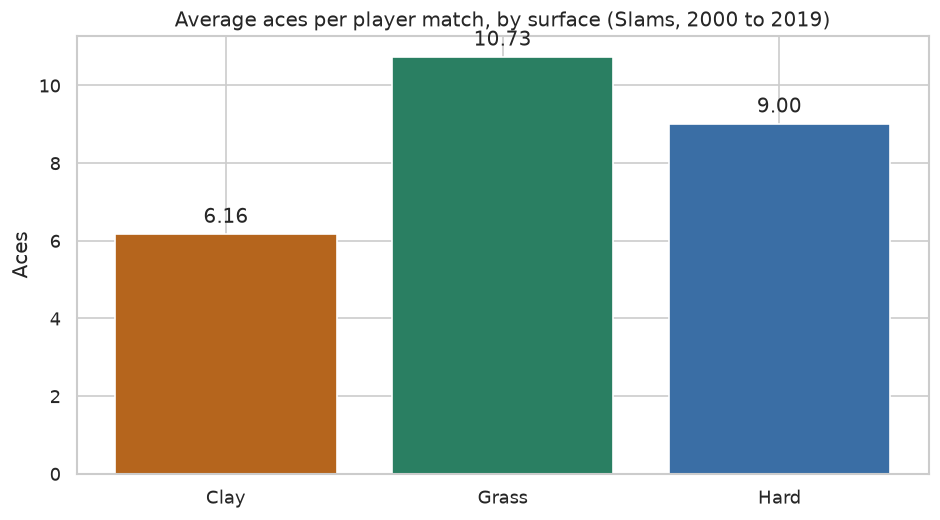

In [4]:
g = df.groupby('surface')[['aces', 'dbl_faults', 'first_won_rate', 'sdi']].mean()
print(g.round(3))
plt.figure(figsize=(8, 4.5)); plt.bar(g.index, g['aces'], color=['#b5651d', '#2a7f62', '#3a6ea5'])
plt.title('Average aces per player match, by surface (Slams, 2000 to 2019)'); plt.ylabel('Aces')
for i, v in enumerate(g['aces']): plt.text(i, v + 0.3, f'{v:.2f}', ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/02_aces_by_surface.png'); plt.show()

## Chart: first serve points won, winners versus losers.

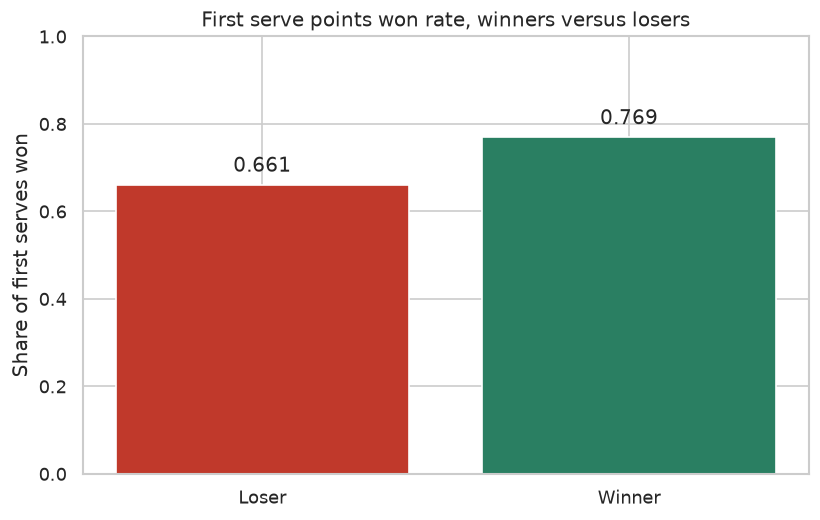

In [5]:
w = df.groupby('winner')['first_won_rate'].mean()
plt.figure(figsize=(7, 4.5)); plt.bar(['Loser', 'Winner'], [w[False], w[True]], color=['#c0392b', '#2a7f62'])
plt.title('First serve points won rate, winners versus losers'); plt.ylabel('Share of first serves won'); plt.ylim(0, 1)
for i, v in enumerate([w[False], w[True]]): plt.text(i, v + 0.03, f'{v:.3f}', ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/02_first_serve_winners_losers.png'); plt.show()

## Chart: SDI leaders. Only players with at least 50 Slam matches are shown, so one great match cannot top the list.

          name  matches  wins  aces_per_match  first_won_rate_mean  sdi_mean
    John Isner      121    76           26.45                 0.80     75.68
  Ivo Karlovic      113    53           28.84                 0.82     73.56
  Milos Raonic      113    82           21.28                 0.81     68.53
  Andy Roddick      176   131           15.45                 0.80     66.39
Kevin Anderson      111    71           17.68                 0.77     63.35
  Nick Kyrgios       61    37           19.44                 0.76     63.22
   Sam Querrey      107    58           17.73                 0.79     59.56
  Pete Sampras       52    42           17.67                 0.81     59.55
 Roger Federer      413   357           10.55                 0.79     58.92
 Gilles Muller       78    36           18.87                 0.77     58.45


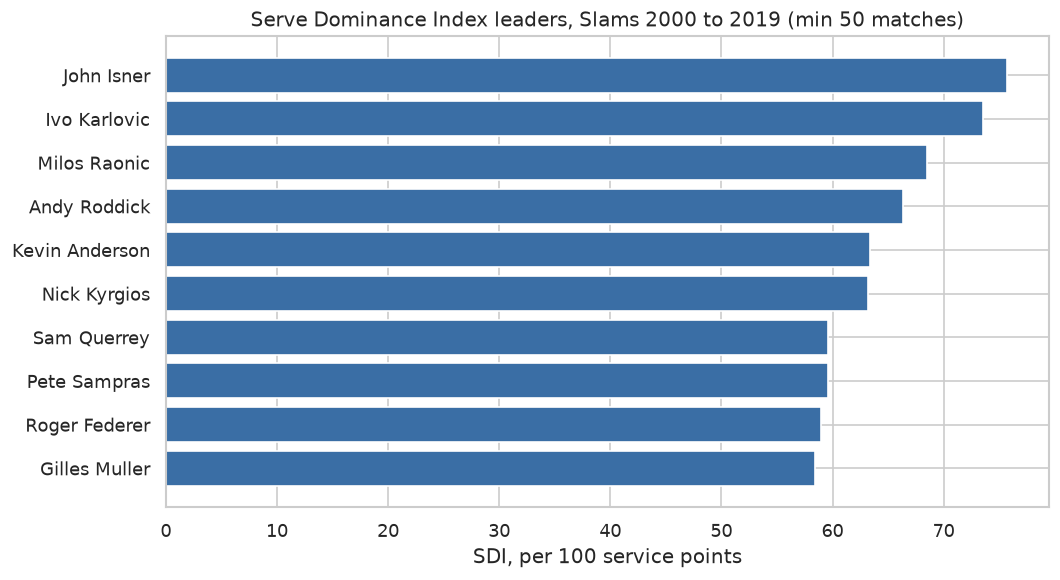

In [6]:
summ = pd.read_csv(f'{PROC}/slam_player_summary.csv')
top = summ[summ.matches >= 50].sort_values('sdi_mean', ascending=False).head(10)
print(top[['name', 'matches', 'wins', 'aces_per_match', 'first_won_rate_mean', 'sdi_mean']].round(2).to_string(index=False))
plt.figure(figsize=(9, 5)); plt.barh(top['name'][::-1], top['sdi_mean'][::-1], color='#3a6ea5')
plt.title('Serve Dominance Index leaders, Slams 2000 to 2019 (min 50 matches)'); plt.xlabel('SDI, per 100 service points')
plt.tight_layout(); plt.savefig(f'{CH}/02_sdi_leaders.png'); plt.show()

## What SDI does not prove

John Isner tops SDI and Ivo Karlovic is second, yet neither won a Slam in this window. A huge serve helps, but return, movement, and holding up over seven matches matter too. The highest SDI among the Big Three is Roger Federer, ahead of Novak Djokovic and Rafael Nadal, even though Nadal won the most Slams here on clay, where aces are rarest. Serve dominance is one skill, not the whole game.

In [7]:
for name in ['Roger Federer', 'Rafael Nadal', 'Novak Djokovic', 'John Isner', 'Ivo Karlovic']:
    r = summ[summ.name == name].iloc[0]
    print(f"{name}: {int(r.matches)} matches, SDI {r.sdi_mean:.2f}, aces per match {r.aces_per_match:.2f}, break points saved {r.bp_save_rate:.3f}")

Roger Federer: 413 matches, SDI 58.92, aces per match 10.55, break points saved 0.681
Rafael Nadal: 309 matches, SDI 53.57, aces per match 4.46, break points saved 0.681
Novak Djokovic: 322 matches, SDI 54.71, aces per match 7.04, break points saved 0.653
John Isner: 121 matches, SDI 75.68, aces per match 26.45, break points saved 0.698
Ivo Karlovic: 113 matches, SDI 73.56, aces per match 28.84, break points saved 0.708
